# Predicting retail crop prices in Rwandan markets

**Mission:** use software engineering and machine learning to solve agricultural challenges in East Africa, so farmers can improve productivity, reach markets and become financially sustainable.

**Use case:** farmers often sell at the farm gate without knowing what their crop is worth in nearby markets. This model predicts the **retail price (RWF per kg)** of a crop in a given Rwandan market, district and month. A farmer or cooperative can use it to decide **where and when to sell**, and to negotiate with buyers. This addresses the mission's "limited access to markets" challenge.

**Dataset:** [WFP Food Prices for Rwanda](https://data.humdata.org/dataset/wfp-food-prices-for-rwanda), published by the World Food Programme on the Humanitarian Data Exchange (HDX). It holds about 158,000 monthly price records from 2000 to 2026 across 100+ markets, with 16 columns: date, province, district, market, market ID, latitude, longitude, category, commodity, commodity ID, unit, price flag, price type, currency, price and USD price. The columns mix numeric and categorical types.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
raw = pd.read_csv("data/wfp_food_prices_rwa.csv", low_memory=False)
# Some HDX exports have a second header row of HXL tags (e.g. "#date"); drop it if present.
raw = raw[~raw["date"].astype(str).str.startswith("#")]
print(raw.shape)

# Hold back the newest months. They play the role of "new data" that arrives after deployment,
# which I upload to the API's /retrain endpoint (saved as API/sample_new_data.csv).
NEW_DATA_FROM = "2026-06-01"
raw_new = raw[raw["date"] >= NEW_DATA_FROM]
raw = raw[raw["date"] < NEW_DATA_FROM]
raw_new.to_csv("../API/sample_new_data.csv", index=False)
print("held back for retraining demo:", raw_new.shape, "| used for training/testing:", raw.shape)
raw.head()

(157793, 16)


held back for retraining demo: (934, 16) | used for training/testing: (156859, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,206.11,0.60
1,2000-01-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,108.02,0.32
2,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,152.66,0.45
3,2000-02-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,pulses and nuts,Beans,50,KG,actual,Wholesale,RWF,110.22,0.32
4,2000-03-15,Kigali City,Nyarugenge,Kigali,1076,-1.95,30.06,cereals and tubers,Maize,51,KG,actual,Wholesale,RWF,159.27,0.47


In [3]:
raw.info()

<class 'pandas.DataFrame'>
Index: 156859 entries, 0 to 157511
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   date          156859 non-null  str    
 1   admin1        156859 non-null  str    
 2   admin2        156859 non-null  str    
 3   market        156859 non-null  str    
 4   market_id     156859 non-null  int64  
 5   latitude      156859 non-null  float64
 6   longitude     156859 non-null  float64
 7   category      156859 non-null  str    
 8   commodity     156859 non-null  str    
 9   commodity_id  156859 non-null  int64  
 10  unit          156859 non-null  str    
 11  priceflag     156859 non-null  str    
 12  pricetype     156859 non-null  str    
 13  currency      156859 non-null  str    
 14  price         156859 non-null  float64
 15  usdprice      156859 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 20.3 MB


In [4]:
for col in ["unit", "pricetype", "priceflag", "currency", "category"]:
    print(col, raw[col].value_counts().to_dict(), "\n")

unit {'KG': 137734, 'Unit': 10485, 'L': 5841, 'Sack': 2799} 

pricetype {'Retail': 156190, 'Wholesale': 669} 



priceflag {'actual': 147664, 'actual,aggregate': 6308, 'aggregate': 2887} 

currency {'RWF': 156859} 



category {'cereals and tubers': 64024, 'vegetables and fruits': 51728, 'meat, fish and eggs': 15785, 'pulses and nuts': 12265, 'miscellaneous food': 4417, 'oil and fats': 3938, 'non-food': 2799, 'milk and dairy': 1903} 



**What the raw data shows.** After holding back June–August 2026, 156,859 rows remain, with **no missing values** in any of the 16 columns. The checks above show why filtering is needed before modelling:
- **unit:** prices are recorded per kg (137,734 rows), per single item (10,485), per litre (5,841) and per sack (2,799). These can't be compared with each other.
- **pricetype:** nearly all rows are retail (156,190); only 669 are wholesale.
- **priceflag:** 147,664 are actual market readings; the rest are averages that WFP computed (`aggregate`), which would count the same market twice.
- **currency:** every price is in RWF, so no currency conversion is needed.

## 2. Clean the data and engineer features

Prices are recorded in different **units** (kg, litre, single item, sack), as **retail or wholesale**, and as **actual** market readings or **aggregates** computed by WFP. Prices in different units or price types can't be compared, so I keep one consistent slice: **retail, actual, per-kg prices**. This is the price a farmer competes with when selling at market, and it still leaves about 129,000 rows.

The cleaning function below is reused by the API's `/retrain` endpoint, so new data is cleaned in exactly the same way.

In [5]:
FEATURES_CAT = ["commodity", "market", "province", "district"]
FEATURES_NUM = ["latitude", "longitude", "year", "month"]
FEATURES = FEATURES_CAT + FEATURES_NUM
TARGET = "price"


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Turn raw WFP rows into the model's feature table (one row = one crop, market, month)."""
    df = df[~df["date"].astype(str).str.startswith("#")].copy()
    df = df[(df["unit"] == "KG") & (df["pricetype"] == "Retail") & (df["priceflag"] == "actual")]
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
    df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")
    date = pd.to_datetime(df["date"], errors="coerce")
    df["year"] = date.dt.year
    df["month"] = date.dt.month
    df = df.rename(columns={"admin1": "province", "admin2": "district"})
    df = df[FEATURES + [TARGET]].dropna()
    df = df[df["price"] > 0].drop_duplicates()
    df[["year", "month"]] = df[["year", "month"]].astype(int)
    return df


def remove_outliers(df: pd.DataFrame) -> pd.DataFrame:
    """Drop prices far outside the normal range *for that commodity* (IQR rule on log price)."""
    logp = np.log(df["price"])
    q1 = logp.groupby(df["commodity"]).transform(lambda s: s.quantile(0.25))
    q3 = logp.groupby(df["commodity"]).transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    keep = (logp >= q1 - 3 * iqr) & (logp <= q3 + 3 * iqr)
    return df[keep]


data = clean(raw)
print("after cleaning:", data.shape)
data = remove_outliers(data).reset_index(drop=True)
print("after outlier removal:", data.shape)
data.head()

after cleaning: (129094, 9)


after outlier removal: (128814, 9)


,commodity,market,province,district,latitude,longitude,year,month,price
0,Cassava,Ruhuha,Eastern Province,Bugesera,-2.15,30.09,2008,1,140.0
1,Cassava flour,Ruhuha,Eastern Province,Bugesera,-2.15,30.09,2008,1,190.0
2,Maize,Ruhuha,Eastern Province,Bugesera,-2.15,30.09,2008,1,150.0
3,Maize flour,Ruhuha,Eastern Province,Bugesera,-2.15,30.09,2008,1,240.0
4,Potatoes (Irish),Ruhuha,Eastern Province,Bugesera,-2.15,30.09,2008,1,120.0


**Cleaning result.** Keeping only retail, actual, per-kg prices leaves **129,094 rows**. I then remove extreme prices per commodity: a price is dropped if its log is more than 3 interquartile ranges below the commodity's 25th percentile or above its 75th. The wide fence (3, not the usual 1.5) removes only values that look like recording errors, not real price spikes. This drops 280 rows (0.2%), leaving **128,814 rows** and the 9 columns shown above (8 features and the price).

**Columns dropped, and why**

| Column | Reason dropped |
|---|---|
| `date` | Split into `year` and `month`, which the models can use as numbers |
| `market_id`, `commodity_id` | ID codes that repeat `market` and `commodity`; they carry no extra information |
| `unit`, `pricetype`, `priceflag`, `currency` | Constant after filtering (KG, Retail, actual, RWF) |
| `category` | Fully determined by `commodity` (maize is always "cereals and tubers"), so it's redundant |
| `usdprice` | The same price converted to dollars. Keeping it would leak the answer into the inputs |

That leaves **8 features**: 4 categorical (`commodity`, `market`, `province`, `district`) and 4 numeric (`latitude`, `longitude`, `year`, `month`). The target is `price` in RWF per kg.

## 3. Explore the data

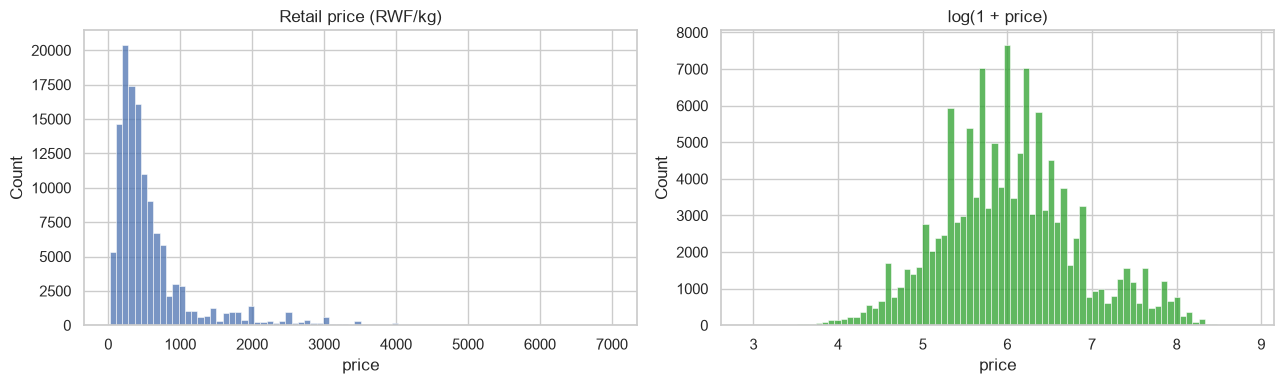

skew raw: 2.7 | skew log: 0.25


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data["price"], bins=80, ax=axes[0])
axes[0].set_title("Retail price (RWF/kg)")
sns.histplot(np.log1p(data["price"]), bins=80, ax=axes[1], color="tab:green")
axes[1].set_title("log(1 + price)")
plt.tight_layout(); plt.show()
print("skew raw:", round(data["price"].skew(), 2), "| skew log:", round(np.log1p(data["price"]).skew(), 2))

**Plot 1 – price distribution.** Raw prices are strongly right-skewed (skew 2.72). Most crops sell for 100–700 RWF/kg, but a few items such as meat, garlic and apples reach several thousand. A model trained on raw prices would spend most of its effort on those few expensive items. After taking `log(1 + price)` the distribution is almost symmetric (skew 0.25). **Decision:** every model learns log price, and predictions are converted back to RWF.

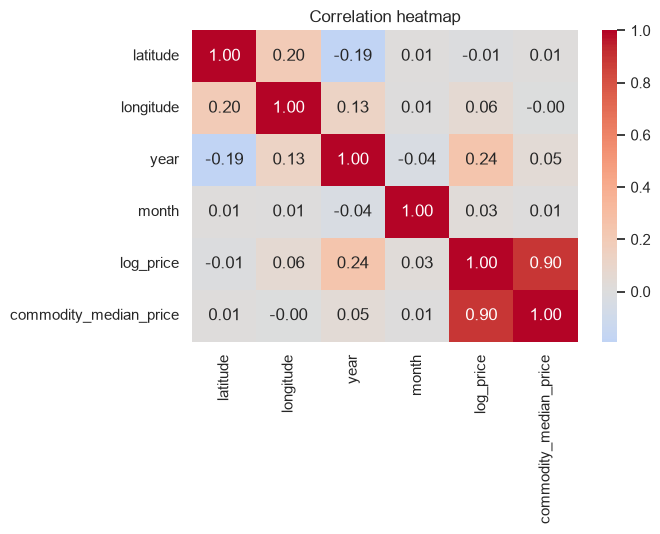

In [7]:
corr_df = data[FEATURES_NUM].copy()
corr_df["log_price"] = np.log1p(data["price"])
# Add each commodity's median price (computed on all rows, used only for this plot) to see how much crop type matters.
corr_df["commodity_median_price"] = np.log1p(data.groupby("commodity")["price"].transform("median"))
plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout(); plt.show()

**Plot 2 – correlation heatmap.** Latitude, longitude and month have almost no *linear* correlation with log price (|r| ≤ 0.06). Year has a moderate positive correlation (0.24), driven by inflation. The strongest signal is the crop itself: a crop's typical price correlates 0.89 with the actual price. **Decisions:** commodity and year are core features. I still keep the location features, because location effects aren't straight lines: a market far from Kigali can be cheaper for one crop and dearer for another, and tree models can learn that. The numeric features are only weakly correlated with each other (at most 0.20), so none has to be dropped for multicollinearity.

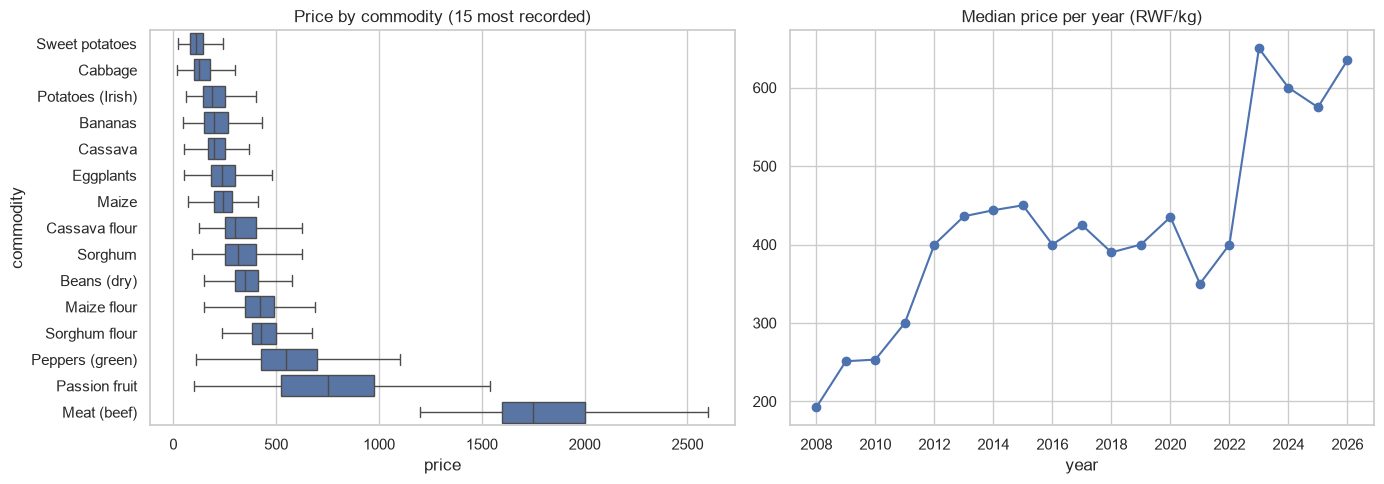

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = data["commodity"].value_counts().head(15).index
order = data[data["commodity"].isin(top)].groupby("commodity")["price"].median().sort_values().index
sns.boxplot(data=data[data["commodity"].isin(top)], y="commodity", x="price", order=order, ax=axes[0], showfliers=False)
axes[0].set_title("Price by commodity (15 most recorded)")
yearly = data.groupby("year")["price"].median()
axes[1].plot(yearly.index, yearly.values, marker="o")
axes[1].set_title("Median price per year (RWF/kg)")
axes[1].set_xlabel("year")
axes[1].xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

**Plot 3 – price by commodity and by year.** Typical prices differ about tenfold between crops, from about 100–150 RWF/kg for sweet potatoes and cabbage to about 1,750 for beef. This confirms commodity must be a feature. The median price roughly tripled between 2008 and 2026, with a sharp jump after 2022 that matches the regional food price inflation of 2022–23. **Decisions:** keep `year` as a feature. I also note that most records come from 2011–2015, so the model is most reliable for those years and less precise for recent ones.

**Which features matter most?** From the plots above, ranked: (1) **commodity**, by far the strongest; (2) **year**, because of inflation; (3) **location** (market, district, province, latitude, longitude), weak on its own but important in combination with the crop; (4) **month**, a small seasonal effect around harvests. The random forest's feature importances in section 7 check this ranking against the trained model.

## 4. Encode, split and standardize

- **Categorical → numeric:** `OneHotEncoder` turns each commodity, market, province and district into its own 0/1 column. `handle_unknown="ignore"` stops a market the model has never seen from crashing a prediction.
- **Split:** 80% train, 20% test. A further 20% of the training rows is set aside as a **validation** set for tuning SGD, so the test set is only used for the final comparison.
- **Standardize:** `StandardScaler` on the numeric columns. Both the encoder and the scaler sit inside a `ColumnTransformer`, which is **fit on the training set only**. The test set is transformed with the training means and standard deviations, so no test information leaks into training.
- **Target:** models learn `log(1 + price)` (see plot 1). All MSE values below are on that log scale. I also report RMSE in RWF so the error is easy to interpret.

In [9]:
X = data[FEATURES]
y = np.log1p(data[TARGET])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=RANDOM_STATE)


def make_preprocessor(encoding="onehot"):
    """One-hot for linear models; ordinal codes for tree models (see section 6)."""
    if encoding == "onehot":
        cat = OneHotEncoder(handle_unknown="ignore")
    else:
        cat = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    return ColumnTransformer([
        ("cat", cat, FEATURES_CAT),
        ("num", StandardScaler(), FEATURES_NUM),
    ])


pre = make_preprocessor().fit(X_train)          # fit on training data only
Xt_train, Xt_test = pre.transform(X_train), pre.transform(X_test)
print("train:", Xt_train.shape, " test:", Xt_test.shape)

train: (103051, 198)  test: (25763, 198)


**Result of encoding.** The 8 input columns become **198 numeric columns**: 4 standardized numbers (latitude, longitude, year, month) plus 194 one-hot columns for the commodities, markets, provinces and districts. Training uses 103,051 rows and testing 25,763.

## 5. Model 1 – Linear regression by gradient descent (`SGDRegressor`)

scikit-learn doesn't record a loss history, so I train with `partial_fit` one epoch at a time. After each epoch I record the MSE. The rows are shuffled before every epoch, which is what "stochastic" gradient descent expects.

**Tuning:** I try every combination of learning rate (`eta0`) and L2 regularization strength (`alpha`) for up to 60 epochs. Each one is scored on the **validation** set, and the best epoch count comes from the same run.

In [10]:
def train_sgd(X_a, y_a, X_b, y_b, eta0, alpha, epochs, seed=RANDOM_STATE):
    """Train SGD epoch by epoch; return the model and the per-epoch MSE on both sets."""
    model = SGDRegressor(eta0=eta0, alpha=alpha, learning_rate="constant", penalty="l2", random_state=seed)
    rng = np.random.default_rng(seed)
    y_a, y_b = np.asarray(y_a), np.asarray(y_b)
    hist_a, hist_b = [], []
    for _ in range(epochs):
        idx = rng.permutation(X_a.shape[0])
        model.partial_fit(X_a[idx], y_a[idx])
        hist_a.append(mean_squared_error(y_a, model.predict(X_a)))
        hist_b.append(mean_squared_error(y_b, model.predict(X_b)))
    return model, hist_a, hist_b


# Tuning uses a preprocessor fit on the tuning-train part only, scored on validation.
pre_tune = make_preprocessor().fit(X_tr)
Xt_tr, Xt_val = pre_tune.transform(X_tr), pre_tune.transform(X_val)

results = []
for eta0 in [0.0001, 0.001, 0.01]:
    for alpha in [1e-6, 1e-4, 1e-2]:
        _, _, val_hist = train_sgd(Xt_tr, y_tr, Xt_val, y_val, eta0, alpha, epochs=60)
        best_epoch = int(np.argmin(val_hist)) + 1
        results.append({"eta0": eta0, "alpha": alpha, "best_epoch": best_epoch,
                        "val_mse_at_best_epoch": min(val_hist), "val_mse_after_60": val_hist[-1]})

tuning = pd.DataFrame(results).sort_values("val_mse_at_best_epoch")
tuning

,eta0,alpha,best_epoch,val_mse_at_best_epoch,val_mse_after_60
3,0.0010,0.000001,38,0.083189,0.083216
4,0.0010,0.000100,38,0.083284,0.083316
6,0.0100,0.000001,42,0.084250,0.084647
7,0.0100,0.000100,42,0.084311,0.084755
0,0.0001,0.000001,60,0.084839,0.084839
1,0.0001,0.000100,60,0.085041,0.085041
8,0.0100,0.010000,27,0.150127,0.152811
5,0.0010,0.010000,60,0.154849,0.154849
2,0.0001,0.010000,59,0.202615,0.202925


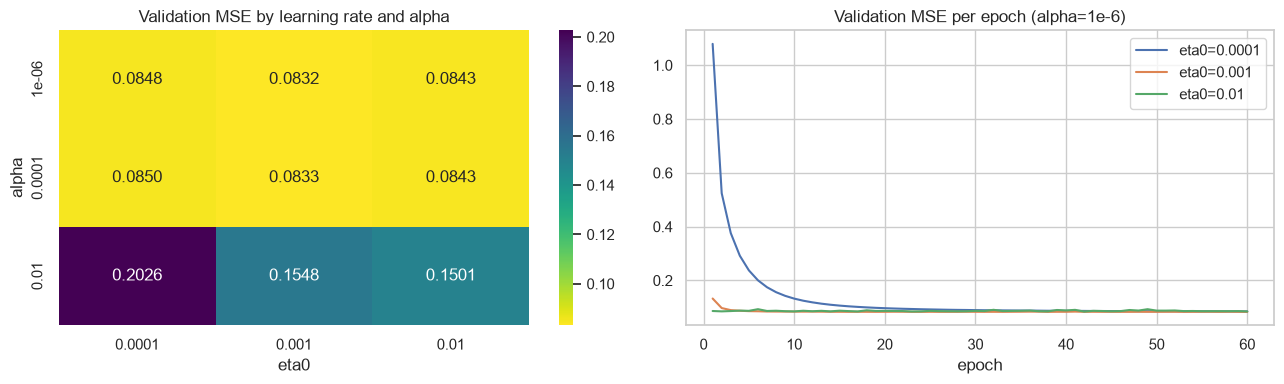

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pivot = tuning.pivot(index="alpha", columns="eta0", values="val_mse_at_best_epoch")
sns.heatmap(pivot, annot=True, fmt=".4f", cmap="viridis_r", ax=axes[0])
axes[0].set_title("Validation MSE by learning rate and alpha")
for eta0 in [0.0001, 0.001, 0.01]:
    _, _, h = train_sgd(Xt_tr, y_tr, Xt_val, y_val, eta0, 1e-6, epochs=60)
    axes[1].plot(range(1, 61), h, label=f"eta0={eta0}")
axes[1].set_title("Validation MSE per epoch (alpha=1e-6)"); axes[1].set_xlabel("epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

**Effect of each hyperparameter.** - **Regularization (`alpha`):** 1e-6 and 1e-4 give almost the same validation MSE (about 0.083). At 1e-2 the error nearly doubles (0.15–0.20): the strong penalty pushes the ~200 crop and market weights towards zero, so the model underfits.
- **Learning rate (`eta0`):** 0.0001 is too slow. It is still improving after 60 epochs (its best epoch is the last). 0.01 learns fast but bounces around and never gets as low (best 0.0843). **0.001** is the best balance, at 0.0832.
- **Epochs:** almost all of the improvement happens in the first 10 epochs, and the curve is flat after about 15. The lowest validation MSE was at epoch 38, so I use 38, although 15 would be nearly as good.

### Loss curve – best SGD settings, train vs test MSE per epoch

best: eta0=0.001, alpha=1e-06, epochs=38


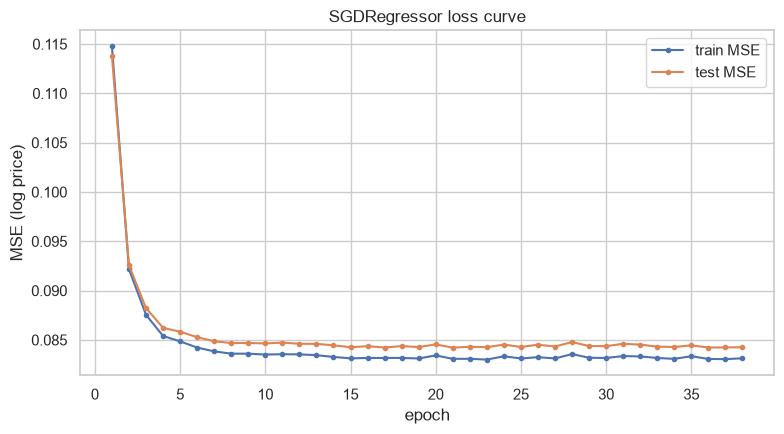

In [12]:
best = tuning.iloc[0]
BEST_ETA0, BEST_ALPHA, BEST_EPOCHS = float(best["eta0"]), float(best["alpha"]), int(best["best_epoch"])
print(f"best: eta0={BEST_ETA0}, alpha={BEST_ALPHA}, epochs={BEST_EPOCHS}")

sgd, train_hist, test_hist = train_sgd(Xt_train, y_train, Xt_test, y_test, BEST_ETA0, BEST_ALPHA, epochs=BEST_EPOCHS)

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, BEST_EPOCHS + 1), train_hist, marker="o", ms=3, label="train MSE")
plt.plot(range(1, BEST_EPOCHS + 1), test_hist, marker="o", ms=3, label="test MSE")
plt.xlabel("epoch"); plt.ylabel("MSE (log price)"); plt.title("SGDRegressor loss curve")
plt.legend(); plt.tight_layout(); plt.show()

Train and test MSE fall sharply in the first few epochs and flatten at about 0.083–0.084 after 10 epochs. The two curves almost overlap, so the model **isn't overfitting**. That flat level is the limit of a *linear* model. It can only add a fixed amount for each crop, market and year, so it can't represent combinations such as "tomatoes are cheap in this region during this season". More epochs won't fix that; a more flexible model is needed.

## 6. Models 2–4 – closed-form linear regression, decision tree, random forest

**Encoding choice for trees.** Linear models need one-hot columns, because a single number per market would imply a false order (market 50 is "more" than market 10). Trees are different. With one-hot columns, each split can only separate *one* market or crop from all the rest, so a tree needs a huge number of splits to learn 107 markets and 53 crops. With **ordinal codes**, one split can put many categories on each side. In a first attempt (one-hot, depth limited to 25), the random forest reached a test MSE of only 0.084, no better than linear regression. Switching to ordinal codes made it about 4× better and about 35× faster to train.

**Forest size.** The API must retrain this model on Render's free plan (512 MB of memory, a small share of one CPU). I compared settings on one CPU core. 50 trees with leaves of at least 3 rows reached a test MSE of 0.0205, but took 68 s to train, needed about 126 MB of memory and made a 39 MB file. **30 trees with leaves of at least 5 rows** reached 0.0227 in 21 s, using about 44 MB and making a 14 MB file. I chose the smaller forest: it gives up a little accuracy so that retraining on Render finishes in minutes rather than timing out.

In [13]:
def make_pipeline(regressor, encoding):
    """Preprocessing + model in one object; the target is log-transformed inside, so predict() returns RWF/kg."""
    return TransformedTargetRegressor(
        regressor=Pipeline([("pre", make_preprocessor(encoding)), ("model", regressor)]),
        func=np.log1p, inverse_func=np.expm1,
    )


candidates = {
    "LinearRegression": (LinearRegression(), "onehot"),
    "DecisionTreeRegressor": (DecisionTreeRegressor(min_samples_leaf=3, random_state=RANDOM_STATE), "ordinal"),
    "RandomForestRegressor": (RandomForestRegressor(n_estimators=30, min_samples_leaf=5, n_jobs=-1,
                                                    random_state=RANDOM_STATE), "ordinal"),
}

X_train_raw, X_test_raw = X_train, X_test
y_train_rwf, y_test_rwf = np.expm1(y_train), np.expm1(y_test)

fitted = {}
for name, (reg, encoding) in candidates.items():
    fitted[name] = make_pipeline(reg, encoding).fit(X_train_raw, y_train_rwf)
    print("trained", name)

trained LinearRegression


trained DecisionTreeRegressor


trained RandomForestRegressor


## 7. Compare all four models

In [14]:
def scores(pred_train_log, pred_test_log, pred_test_rwf):
    return {
        "train_MSE": mean_squared_error(y_train, pred_train_log),
        "test_MSE": mean_squared_error(y_test, pred_test_log),
        "test_RMSE_RWF": np.sqrt(mean_squared_error(y_test_rwf, pred_test_rwf)),
    }

rows = {"SGDRegressor": scores(sgd.predict(Xt_train), sgd.predict(Xt_test), np.expm1(sgd.predict(Xt_test)))}
for name, m in fitted.items():
    p_tr, p_te = m.predict(X_train_raw), m.predict(X_test_raw)
    rows[name] = scores(np.log1p(p_tr), np.log1p(p_te), p_te)

comparison = pd.DataFrame(rows).T.sort_values("test_MSE")
comparison.style.format({"train_MSE": "{:.4f}", "test_MSE": "{:.4f}", "test_RMSE_RWF": "{:,.0f}"})

,train_MSE,test_MSE,test_RMSE_RWF
RandomForestRegressor,0.0144,0.0229,105
DecisionTreeRegressor,0.0091,0.0267,111
LinearRegression,0.0829,0.0841,194
SGDRegressor,0.0831,0.0843,194


In [15]:
BEST_NAME = comparison.index[0]
print("Best model (lowest test MSE):", BEST_NAME)

Best model (lowest test MSE): RandomForestRegressor


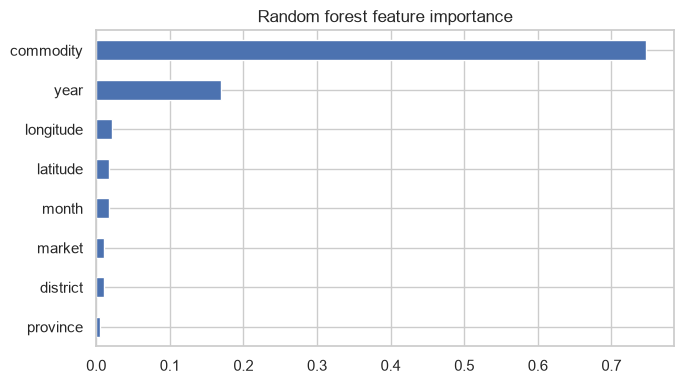

commodity    0.748
year         0.169
longitude    0.021
latitude     0.018
month        0.017
market       0.011
district     0.010
province     0.006
dtype: float64

In [16]:
rf = fitted["RandomForestRegressor"].regressor_.named_steps["model"]
importances = pd.Series(rf.feature_importances_, index=FEATURES_CAT + FEATURES_NUM).sort_values()
importances.plot.barh(figsize=(7, 4), title="Random forest feature importance")
plt.tight_layout(); plt.show()
importances.sort_values(ascending=False).round(3)

**Best model and why.** The best model is the one with the **lowest test MSE**. **Random forest** has the lowest test MSE: 0.0229 on log price, a typical error of about 15% or an RMSE of 105 RWF/kg. That's almost 4× lower than both linear models (0.084) and better than a single decision tree (0.027).

How the dataset affected each model:
- **SGD and closed-form linear regression** give almost identical results, as expected: they fit the same equation, one by gradient descent and one exactly. Their train and test MSE are equal and high, a sign of underfitting. In this data, price depends on *combinations* of crop, market and year, and a sum of separate effects can't capture that.
- **The decision tree** can model those combinations, so its error falls sharply. But its train MSE (0.009) is much lower than its test MSE (0.027), so it partly memorizes noise in individual price readings.
- **The random forest** averages 30 trees, each trained on a different random sample of rows. It keeps the trees' flexibility but cancels much of their noise, giving the best test MSE. Its train–test gap (0.014 vs 0.023) shows some overfitting remains, but less than the single tree.

For a farmer choosing where to sell, accuracy in RWF is what matters, so the random forest is the model I save and deploy. Its feature importances confirm the ranking from section 3: commodity (0.75), then year (0.17), then the five location features together (about 0.07) and month (0.02).

## 8. Scatter plots – most correlated feature vs target

Of the numeric features, `year` has the strongest correlation with log price (see the heatmap). The first plot shows the raw relationship. The second adds the line from a **one-feature** linear regression, fit only for this plot.

most correlated numeric feature: year 0.242


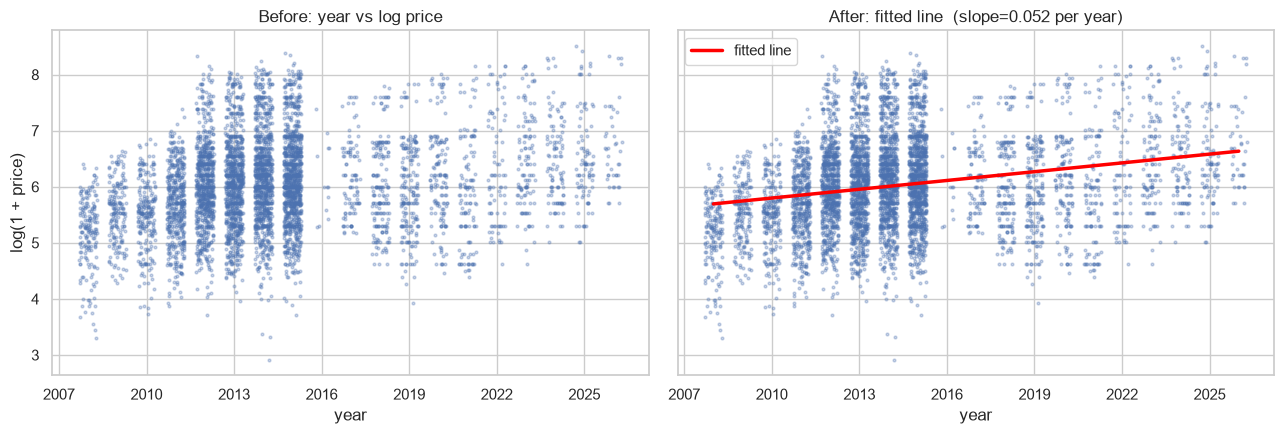

In [17]:
num_corr = corr_df[FEATURES_NUM + ["log_price"]].corr()["log_price"].drop("log_price").abs()
TOP_FEATURE = num_corr.idxmax()
print("most correlated numeric feature:", TOP_FEATURE, round(num_corr.max(), 3))

sample = data.sample(6000, random_state=RANDOM_STATE)
x_s = sample[TOP_FEATURE] + np.random.default_rng(0).uniform(-0.3, 0.3, len(sample))   # jitter so points don't stack
y_s = np.log1p(sample["price"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].scatter(x_s, y_s, s=4, alpha=0.3)
axes[0].set_title(f"Before: {TOP_FEATURE} vs log price")

one = LinearRegression().fit(data[[TOP_FEATURE]], np.log1p(data["price"]))
xs = np.linspace(data[TOP_FEATURE].min(), data[TOP_FEATURE].max(), 100)
axes[1].scatter(x_s, y_s, s=4, alpha=0.3)
axes[1].plot(xs, one.predict(pd.DataFrame({TOP_FEATURE: xs})), color="red", lw=2.5, label="fitted line")
axes[1].set_title(f"After: fitted line  (slope={one.coef_[0]:.3f} per {TOP_FEATURE})")
axes[1].legend()
for ax in axes:
    ax.set_xlabel(TOP_FEATURE); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("log(1 + price)")
plt.tight_layout(); plt.show()

**Before:** log price rises with year, but the spread within each year is huge, because each year contains many different crops. **After:** the fitted line has a slope of 0.052, meaning prices rose about 5% per year on average (e^0.052 ≈ 1.05). The line captures the trend but explains little of the spread (correlation 0.24). This shows why one feature isn't enough and the full multivariate model is needed.

## 9. Save the best model with its preprocessing

The saved object is a `TransformedTargetRegressor` wrapping a `Pipeline` of `ColumnTransformer` (one-hot encoder and scaler) and the model. One `predict()` call takes raw inputs and returns RWF per kg. I also save the cleaned training rows: the API needs them to refit the model when new data is uploaded to `/retrain`. The held-back June–August 2026 rows were already saved as `API/sample_new_data.csv` for testing `/retrain`.

In [18]:
if BEST_NAME == "SGDRegressor":
    # Wrap the SGD model with the preprocessor it was trained with, so it also accepts raw inputs.
    best_model = TransformedTargetRegressor(regressor=Pipeline([("pre", pre), ("model", sgd)]),
                                            func=np.log1p, inverse_func=np.expm1, check_inverse=False)
    best_model.regressor_ = best_model.regressor
    best_model._training_dim = 1
else:
    best_model = fitted[BEST_NAME]

joblib.dump(best_model, "../API/best_model.pkl", compress=3)
data.to_csv("../API/training_data.csv", index=False)

import os
print("saved best_model.pkl:", round(os.path.getsize("../API/best_model.pkl") / 1e6, 1), "MB")

saved best_model.pkl: 14.0 MB


## 10. Load the saved model and predict one row of the test set

In [19]:
def predict_price(row: dict, model_path: str = "../API/best_model.pkl") -> float:
    """Load the saved model and return the predicted retail price (RWF/kg) for one input row."""
    model = joblib.load(model_path)
    return float(model.predict(pd.DataFrame([row])[FEATURES])[0])


one_row = X_test.iloc[0].to_dict()
actual = float(np.expm1(y_test.iloc[0]))
print("input:", one_row)
print(f"predicted: {predict_price(one_row):,.0f} RWF/kg  |  actual: {actual:,.0f} RWF/kg")

input: {'commodity': 'Meat (beef)', 'market': 'Kabeza', 'province': 'Eastern Province', 'district': 'Kirehe', 'latitude': -2.31, 'longitude': 30.83, 'year': 2020, 'month': 12}


predicted: 2,965 RWF/kg  |  actual: 3,000 RWF/kg


**Check.** For a beef price in Kabeza market (Kirehe district, December 2020), the saved model predicts **2,965 RWF/kg** against a real price of **3,000 RWF/kg**, about 1% off. This is the same function the API calls in `/predict`, so the deployed model gives the same answer.

## 11. Summary

- **Data:** 128,814 retail per-kg crop prices from Rwandan markets (WFP, 2008 to May 2026), with 8 features. June–August 2026 is held back as new data for testing `/retrain`.
- **Best model:** `RandomForestRegressor`, test MSE 0.0229 (log price), about 105 RWF/kg RMSE. It's saved with its preprocessing to `API/best_model.pkl`.
- **Linear models** plateau at a test MSE of 0.084 because price depends on interactions between crop, place and time.
- **To reduce the loss further:** add features that drive prices (rainfall, harvest season, fuel prices, exchange rate), add more recent data (most rows are from 2011–2015), and tune the forest (`n_estimators`, `max_features`, `min_samples_leaf`) or try gradient boosting.